# 05. Сравнение rrBLUP, somer и BLUPF90


In [1]:
knitr::opts_chunk$set(
  echo = TRUE,
  message = FALSE,
  warning = FALSE,
  fig.width = 9,
  fig.height = 5
)


# О документе

Отчёт сравнивает три реализации BLUP: rrBLUP, somer и BLUPF90. Сначала по времени счёта, затем по согласованности EBV на одном тестовом датасете.

| | |
|---|---|
| **Данные** | `data/phenotypes.csv`, `data/pedigree.csv` |
| **Цель** | Сопоставить производительность и ранжирование животных |
| **Результат** | Таблица времени, корреляции Спирмена и графики Бланда–Альтмана |


In [2]:
library(ggplot2)
library(rrBLUP)
library(AGHmatrix)
library(pedigreeTools)
library(sommer)
library(dplyr)
library(knitr)


Loading required package: Matrix


Loading required package: MASS


Loading required package: crayon



Attaching package: ‘crayon’



The following object is masked from ‘package:ggplot2’:

    %+%




Attaching package: ‘sommer’



The following objects are masked from ‘package:rrBLUP’:

    A.mat, GWAS




Attaching package: ‘dplyr’



The following object is masked from ‘package:MASS’:

    select



The following objects are masked from ‘package:stats’:

    filter, lag



The following objects are masked from ‘package:base’:

    intersect, setdiff, setequal, union



# 1. Введение

Оценка племенной ценности (EBV, estimated breeding value) — это прогноз генетической ценности животного для селекции. На практике EBV почти никогда не равен фенотипу: на продуктивность влияют возраст, сезон, хозяйство и случайные отклонения. Метод BLUP отделяет эти систематические факторы от генетического эффекта и использует родословную, чтобы «поделиться» информацией между родственниками.

В этом отчёте сравниваются три реализации одной и той же идеи:

- **rrBLUP** — пакет R для смешанных моделей и геномной селекции (`mixed.solve`);
- **somer / sommer** — пакет R для смешанных моделей (`mmes`);
- **BLUPF90** — специализированное семейство программ для генетической оценки животных.

Две задачи:

1. Сравнить **производительность** (время счёта) при росте числа животных. Эти замеры сделаны ранее и приведены как готовые результаты.
2. На **сгенерированном** тестовом датасете посчитать EBV в rrBLUP и somer и проверить, насколько они близки друг к другу и к **известной истинной** племенной ценности. Истина известна только потому, что данные смоделированы: в реальной популяции её нет.

## Характеристика системы (для замеров производительности)

**Процессор:** 11th Gen Intel(R) Core(TM) i5-11400 @ 2.60GHz

**Оперативная память:** 16,0 ГБ (доступно: 15,6 ГБ)

**Видеоадаптер:** Intel(R) UHD Graphics 730 (128 MB)

## Программное обеспечение

**rrBLUP (Ridge Regression Best Linear Unbiased Prediction)** — пакет R Джеффри Эндельмана (2011). Он умеет оценивать эффекты SNP-маркеров ридж-регрессией и считать BLUP по матрице родства или по геномному ядру. В этом отчёте используется классический BLUP по родословной: случайный эффект животного связан матрицей родства A.

**somer (Sparse Orthogonal Mixed Model Efficiently in R, пакет `sommer`)** — библиотека Джованни Коваррубиаса-Пасарана для смешанных моделей. Её применяют в геномной селекции, при оценке племенной ценности, повторных измерениях и многомерном генетическом анализе. Здесь случайный эффект животного задаётся через `vsm(ism(animal), Gu = A)`.

**BLUPF90** — набор программ для генетической оценки животных методом BLUP. В разделе производительности он участвует как эталон по скорости. В разделе валидации BLUPF90 не запускается: внешние решения были бы привязаны к другой базе животных, а тестовый датасет создаётся заново внутри отчёта.

# 2. Производительность

Ниже — ранее измеренное время счёта (и прогноз по логарифмической регрессии для больших N). Память для BLUPF90 в этой таблице не сравнивается: для него сохранились только замеры времени.

Интерпретация графика простая: чем правее точка, тем больше животных; чем выше линия, тем дольше считается оценка.


In [3]:
cur_time <- c(0.009, 3.938, 492.892, 6860.510)
cur_memory <- c(0.00432, 0.372, 9.14, 36.5)
cur_animals <- c(100, 1000, 5000, 10000)
new_animals <- c(50000, 100000, 500000, 1000000)

log_animals <- log10(cur_animals)
model_time <- lm(log10(cur_time) ~ log_animals)
model_memory <- lm(log10(cur_memory) ~ log_animals)
log_new_animals <- log10(new_animals)
new_time <- 10^predict(model_time, newdata = data.frame(log_animals = log_new_animals))
new_memory <- 10^predict(model_memory, newdata = data.frame(log_animals = log_new_animals))

rrblup_df <- data.frame(
  animals = c(cur_animals, new_animals),
  time = c(cur_time, new_time),
  memory = c(cur_memory, new_memory)
)


In [4]:
cur_time <- c(0.09, 17.78, 2314.27)
cur_memory <- c(0.019, 1.23, 30.6)
cur_animals <- c(100, 1000, 5000)
new_animals <- c(10000, 50000, 100000, 500000, 1000000)

log_animals <- log10(cur_animals)
model_time <- lm(log10(cur_time) ~ log_animals)
model_memory <- lm(log10(cur_memory) ~ log_animals)
log_new_animals <- log10(new_animals)
new_time <- 10^predict(model_time, newdata = data.frame(log_animals = log_new_animals))
new_memory <- 10^predict(model_memory, newdata = data.frame(log_animals = log_new_animals))

somer_df <- data.frame(
  animals = c(cur_animals, new_animals),
  time = c(cur_time, new_time),
  memory = c(cur_memory, new_memory)
)


In [5]:
blupf90_df <- data.frame(
  animals = c(100, 1000, 10000, 100000, 1000000),
  time = c(2.77240, 3.16208, 6.989, 71.16657, 6952.95840)
)


In [6]:
df <- rrblup_df %>%
  left_join(somer_df, by = 'animals', suffix = c('_rrblup', '_sommer')) %>%
  left_join(blupf90_df, by = 'animals') %>%
  rename(time_blupf90 = time) %>%
  filter(animals %in% c(100, 1000, 10000, 100000, 1000000)) %>%
  mutate(
    time_rrblup = round(time_rrblup / 60, 2),
    time_sommer = round(time_sommer / 60, 2),
    time_blupf90 = round(time_blupf90 / 60, 3),
    memory_rrblup = round(memory_rrblup, 3),
    memory_sommer = round(memory_sommer, 3)
  )


In [7]:
print(knitr::kable(
  df,
  col.names = c('Животных', 'Время rrBLUP, мин', 'Память rrBLUP, Гб',
                'Время somer, мин', 'Память somer, Гб', 'Время BLUPF90, мин'),
  caption = 'Время и память при разном числе животных. Для больших N время rrBLUP и somer спрогнозировано по логарифмической регрессии.'
))




Table: Время и память при разном числе животных. Для больших N время rrBLUP и somer спрогнозировано по логарифмической регрессии.

| Животных| Время rrBLUP, мин| Память rrBLUP, Гб| Время somer, мин| Память somer, Гб| Время BLUPF90, мин|
|--------:|-----------------:|-----------------:|----------------:|----------------:|------------------:|
|    1e+02|              0.00|             0.004|             0.00|            0.019|              0.046|
|    1e+03|              0.07|             0.372|             0.30|            1.230|              0.053|
|    1e+04|            114.34|            36.500|           175.76|          105.360|              0.116|
|    1e+05|          62474.65|          3278.610|         66078.70|         8035.463|              1.186|
|    1e+06|       50315747.69|        301234.737|      24842996.44|       612839.084|            115.883|


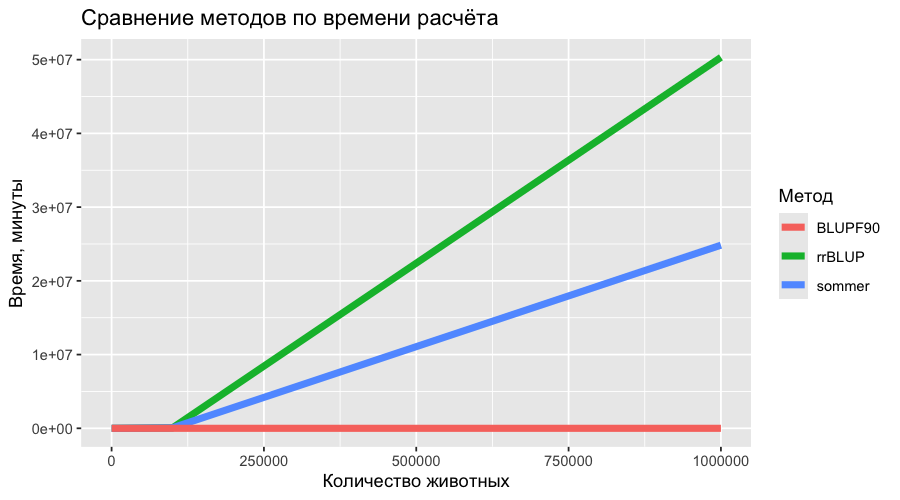

In [8]:
ggplot(df, aes(x = animals)) +
  geom_line(aes(y = time_rrblup, color = 'rrBLUP'), linewidth = 2) +
  geom_line(aes(y = time_sommer, color = 'sommer'), linewidth = 2) +
  geom_line(aes(y = time_blupf90, color = 'BLUPF90'), linewidth = 2) +
  labs(
    color = 'Метод',
    title = 'Сравнение методов по времени расчёта',
    x = 'Количество животных',
    y = 'Время, минуты'
  )


На малых выборках разница ещё умеренная. При десятках и сотнях тысяч животных rrBLUP и somer растут заметно быстрее BLUPF90: специализированный солвер лучше масштабируется.

# 3. Тестовый датасет

Для валидации используется сгенерированный датасет из CSV (`data/phenotypes.csv`, `data/pedigree.csv`). Его создаёт скрипт `tools/generate_data.R`. В таблицах есть родословная, фенотипы и колонка `tbv` — истинная племенная ценность, заложенная при симуляции.

Модель фенотипа:

$$\text{trait} = \beta_{\text{age}}\cdot\text{age} + \beta_{\text{rv}}\cdot\text{rodilsya\_vskolki} + a + e$$

где $a$ — истинная аддитивная племенная ценность (TBV), $e$ — случайный остаток.


In [9]:
phenotypes <- read.csv('data/phenotypes.csv') %>%
  dplyr::select(animal, age, rodilsya_vskolki, trait, tbv) %>%
  mutate(animal = as.factor(animal))
pedigree <- read.csv('data/pedigree.csv')
n_animals <- nrow(phenotypes)


Фрагменты данных:


In [10]:
print(knitr::kable(head(pedigree, 8), caption = 'Родословная: animal, отец (sire), мать (dam). У основателей родители равны 0.'))
print(knitr::kable(head(phenotypes, 8), digits = 3, caption = 'Фенотипы: фиксированные эффекты, признак trait и истинная племенная ценность tbv.'))




Table: Родословная: animal, отец (sire), мать (dam). У основателей родители равны 0.

| animal| sire| dam|
|------:|----:|---:|
|      1|    0|   0|
|      2|    0|   0|
|      3|    0|   0|
|      4|    0|   0|
|      5|    0|   0|
|      6|    0|   0|
|      7|    0|   0|
|      8|    0|   0|




Table: Фенотипы: фиксированные эффекты, признак trait и истинная племенная ценность tbv.

|animal |    age| rodilsya_vskolki|  trait|    tbv|
|:------|------:|----------------:|------:|------:|
|1      | -0.406|           -0.318|  0.819|  0.948|
|2      |  0.527|           -0.254|  3.470| -1.202|
|3      |  0.240|            0.639| -0.928| -0.466|
|4      |  0.898|            0.821| -0.280| -0.269|
|5      |  0.488|            2.335| -0.441| -0.391|
|6      |  0.112|           -0.983| -0.196|  1.349|
|7      |  0.998|           -0.707|  0.962| -0.023|
|8      |  1.192|            0.644| -1.158|  0.244|


# 4. Расчёт оценок

Оба метода решают смешанную модель одного вида:

- фиксированная часть — `age` и `rodilsya_vskolki` (матрица X);
- случайная часть — эффект животного (матрица Z);
- родство животных — матрица A, построенная по родословной.

Матрица A отвечает на вопрос «насколько два животных родственны по родословной». Диагональ — 1 плюс инбридинг, вне диагонали — коэффициент родства. Без A метод не отличил бы родственника от чужого животного.

## 4.1. rrBLUP

Пакет `rrBLUP` считает BLUP функцией `mixed.solve`. Ей передаются признак `y`, матрица фиксированных эффектов `X`, инцидентность животных `Z` и матрица родства `K = A`. На выходе `u` — EBV.


In [11]:
rrBLUP_function <- function(phenotypes, pedigree) {
  common_levels <- levels(as.factor(unique(c(
    as.character(phenotypes$animal), pedigree$animal, pedigree$dam, pedigree$sire
  ))))

  pedigree <- pedigree %>%
    filter((animal %in% phenotypes$animal) | (dam %in% phenotypes$animal) | (sire %in% phenotypes$animal))
  phenotypes <- phenotypes %>%
    filter(animal %in% pedigree$animal)

  pedigree_bl <- pedigree %>%
    mutate(across(c(animal, dam, sire), ~ as.integer(factor(., levels = common_levels))))
  phenotypes_bl <- phenotypes %>%
    mutate(animal = as.integer(factor(animal, levels = common_levels)))

  pedigree_bl <- editPed(
    label = pedigree_bl$animal,
    dam = pedigree_bl$dam,
    sire = pedigree_bl$sire
  )[c('label', 'sire', 'dam')]
  pedigree_bl <- pedigree_bl %>%
    filter(label %in% phenotypes_bl$animal)

  pedigree_bl$sire[!(pedigree_bl$sire %in% pedigree_bl$label)] <- 0
  pedigree_bl$dam[!(pedigree_bl$dam %in% pedigree_bl$label)] <- 0
  rownames(pedigree_bl) <- pedigree_bl$label

  A <- Amatrix(pedigree_bl, ploidy = 2)
  rownames(A) <- as.numeric(rownames(A))
  A_animals <- rownames(A)

  phenotypes_bl <- phenotypes_bl[phenotypes_bl$animal %in% as.numeric(A_animals), ]
  phenotypes_bl <- phenotypes_bl[order(match(phenotypes_bl$animal, as.numeric(A_animals))), ]
  phenotypes_bl$animal <- factor(phenotypes_bl$animal, levels = as.numeric(A_animals))

  X <- model.matrix(~ age + rodilsya_vskolki, data = phenotypes_bl)
  Z <- model.matrix(~ 0 + animal, data = phenotypes_bl)
  K <- A[A_animals, A_animals]

  res <- mixed.solve(y = phenotypes_bl$trait, X = X, Z = Z, K = K)
  names(res$u) <- gsub("[^0-9]", "", names(res$u))
  names(res$u) <- common_levels[as.numeric(names(res$u))]

  solutions <- data.frame(ebv = as.numeric(res$u), animal = names(res$u))
  solutions[, c('animal', 'ebv')]
}


In [12]:
rrblup_solutions <- rrBLUP_function(phenotypes, pedigree)


Verifying conflicting data... 
Organizing data... 
Your data was chronologically organized with success. 
Constructing matrix A using ploidy = 2 
Completed! Time = 0.0001166667  minutes 


## 4.2. somer

Пакет `sommer` оценивает ту же модель формулой. Фиксированные эффекты записываются как в обычном `lm`, случайный эффект животного — через `vsm(ism(animal), Gu = A)`, где `Gu` и есть матрица родства. `rcov = ~ units` задаёт независимые остатки.


In [13]:
SOMER_function <- function(phenotypes, pedigree) {
  pedigree <- pedigree %>%
    filter((animal %in% phenotypes$animal) | (dam %in% phenotypes$animal) | (sire %in% phenotypes$animal))
  phenotypes <- phenotypes %>%
    filter(animal %in% pedigree$animal)

  animals <- na.omit(unique(c(
    as.character(phenotypes$animal), pedigree$animal, pedigree$dam, pedigree$sire
  )))
  common_levels <- levels(as.factor(animals))

  pedigree_bl <- pedigree %>%
    mutate(across(c(animal, dam, sire), ~ as.integer(factor(., levels = common_levels))))
  phenotypes_bl <- phenotypes %>%
    mutate(animal = as.integer(factor(animal, levels = common_levels)))

  pedigree_bl <- editPed(
    label = pedigree_bl$animal,
    dam = pedigree_bl$dam,
    sire = pedigree_bl$sire
  )[c('label', 'sire', 'dam')]
  pedigree_bl$sire[!(pedigree_bl$sire %in% pedigree_bl$label)] <- 0
  pedigree_bl$dam[!(pedigree_bl$dam %in% pedigree_bl$label)] <- 0
  rownames(pedigree_bl) <- pedigree_bl$label

  A <- Amatrix(pedigree_bl[, c('label', 'sire', 'dam')], ploidy = 2)
  full_data <- phenotypes_bl %>%
    mutate(animal = factor(animal, levels = rownames(A)))

  res <- mmes(
    trait ~ age + rodilsya_vskolki,
    random = ~ vsm(ism(animal), Gu = A),
    rcov = ~ units,
    data = full_data,
    verbose = FALSE
  )

  bu <- if (is.null(dim(res$bu))) res$bu else res$bu[, 1]
  nms <- names(bu)
  if (is.null(nms) || !any(nzchar(nms))) nms <- rownames(res$bu)
  keep <- grepl('^[0-9]+$', nms)
  bu <- bu[keep]
  nms <- nms[keep]
  orig <- common_levels[as.integer(nms)]
  animal <- ifelse(is.na(orig), nms, orig)
  data.frame(animal = as.character(animal), ebv = as.numeric(bu), row.names = NULL)
}


In [14]:
somer_solutions <- SOMER_function(phenotypes, pedigree)
somer_solutions$animal <- as.character(somer_solutions$animal)
rrblup_solutions$animal <- as.character(rrblup_solutions$animal)


Verifying conflicting data... 
Organizing data... 
Your data was chronologically organized with success. 
Constructing matrix A using ploidy = 2 
Completed! Time = 0.0001333333  minutes 
Version out of date. Please update sommer to the newest version using:
install.packages('sommer') in a new session
 Use the 'dateWarning' argument to disable the warning message.


Истинная племенная ценность уже есть в колонке `tbv` тестового датасета — отдельная программа для «эталона» не нужна.


In [15]:
true_solutions <- phenotypes %>%
  transmute(animal = as.character(animal), ebv = tbv)


# 5. Сравнение оценок

Сравниваем три вектора одного и того же набора животных:

- EBV из rrBLUP;
- EBV из somer;
- истинный TBV, заложенный при генерации.

Как читаются проверки:

- **Шапиро–Уилк** решает, считать ли распределение нормальным. Если нет — для сдвига используем тест Манна–Уитни, а не Стьюдента.
- **Корреляция Спирмена** показывает, совпадает ли *ранжирование* животных: важно для отбора лучших.
- **Линейная регрессия** показывает, пропорциональны ли шкалы двух оценок.
- **График Бланда–Альтмана** — разность оценок против их среднего. Если точки лежат около нуля без веера, методы согласованы; систематический сдвиг виден как смещение облака вверх или вниз.


In [16]:
correlation_func <- function(dataset, var_1, var_2, m = 'spearman') {
  cor(dataset[[var_1]], dataset[[var_2]], method = m)
}

relevance_func <- function(dataset, var_1, var_2) {
  x <- dataset[[var_1]]; y <- dataset[[var_2]]
  x <- x[is.finite(x)]; y <- y[is.finite(y)]
  if (length(x) < 3 || length(y) < 3) {
    print('Недостаточно наблюдений для теста сдвига')
    return(invisible(NULL))
  }
  p1 <- shapiro.test(x)$p.value
  p2 <- shapiro.test(y)$p.value
  if (p1 > 0.05 && p2 > 0.05) {
    print('Распределение нормальное. Применён тест Стьюдента')
    t.test(dataset[[var_1]], dataset[[var_2]], paired = TRUE, alternative = 'two.sided')
  } else {
    print('Распределение ненормальное. Применён тест Манна-Уитни')
    wilcox.test(dataset[[var_1]], dataset[[var_2]], paired = TRUE, alternative = 'two.sided')
  }
}

bland_altman_plot_func <- function(dataset, var_1, var_2, title) {
  diff_vals <- dataset[[var_1]] - dataset[[var_2]]
  dataset %>%
    mutate(
      mean = (dataset[[var_1]] + dataset[[var_2]]) / 2,
      diff = diff_vals
    ) %>%
    ggplot(aes(x = mean, y = diff)) +
    geom_point(alpha = 0.6) +
    geom_hline(yintercept = 0, linetype = 'dashed') +
    geom_hline(
      yintercept = mean(diff_vals) + c(-1.96, 1.96) * sd(diff_vals),
      color = 'red',
      linetype = 'dotted'
    ) +
    labs(title = title, x = 'Среднее двух оценок', y = 'Разность оценок')
}

linear_regression_func <- function(dataset, var_1, var_2) {
  summary(lm(dataset[[var_1]] ~ dataset[[var_2]]))
}

plot_func <- function(dataset, var_1, var_2, xlab, ylab, title) {
  plot(
    dataset[[var_2]],
    dataset[[var_1]],
    xlab = xlab,
    ylab = ylab,
    main = title,
    pch = 16,
    col = adjustcolor('steelblue', alpha.f = 0.6)
  )
  abline(lm(dataset[[var_1]] ~ dataset[[var_2]]), col = 'red', lwd = 2)
}


In [17]:
compare_rrblup_true <- rrblup_solutions %>%
  inner_join(true_solutions, by = 'animal', suffix = c('_rrblup', '_true'))

compare_somer_true <- somer_solutions %>%
  inner_join(true_solutions, by = 'animal', suffix = c('_somer', '_true'))

compare_rrblup_somer <- rrblup_solutions %>%
  inner_join(somer_solutions, by = 'animal', suffix = c('_rrblup', '_somer'))

spearman_rrblup_true <- correlation_func(compare_rrblup_true, 'ebv_rrblup', 'ebv_true')
spearman_somer_true <- correlation_func(compare_somer_true, 'ebv_somer', 'ebv_true')
spearman_rrblup_somer <- correlation_func(compare_rrblup_somer, 'ebv_rrblup', 'ebv_somer')


In [18]:
print(knitr::kable(head(compare_rrblup_somer, 8), digits = 3,
                    caption = 'EBV rrBLUP и somer (фрагмент)'))
print(data.frame(
  pair = c('rrBLUP vs TBV', 'somer vs TBV', 'rrBLUP vs somer'),
  spearman = round(c(spearman_rrblup_true, spearman_somer_true, spearman_rrblup_somer), 4)
))




Table: EBV rrBLUP и somer (фрагмент)

|animal | ebv_rrblup| ebv_somer|
|:------|----------:|---------:|
|1      |      0.117|     0.117|
|2      |      0.064|     0.064|
|3      |      0.072|     0.072|
|4      |      0.014|     0.014|
|5      |     -0.150|    -0.151|
|6      |      0.074|     0.074|
|7      |      0.083|     0.083|
|8      |     -0.031|    -0.031|


             pair spearman
1   rrBLUP vs TBV   0.5372
2    somer vs TBV   0.5373
3 rrBLUP vs somer   1.0000


## 5.1. rrBLUP и истинная племенная ценность


[1] "Распределение нормальное. Применён тест Стьюдента"



	Paired t-test

data:  dataset[[var_1]] and dataset[[var_2]]
t = -0.28222, df = 199, p-value = 0.7781
alternative hypothesis: true mean difference is not equal to 0
95 percent confidence interval:
 -0.13194249  0.09890399
sample estimates:
mean difference 
    -0.01651925 



[1] 0.5371754



Call:
lm(formula = dataset[[var_1]] ~ dataset[[var_2]])

Residuals:
     Min       1Q   Median       3Q      Max 
-0.21582 -0.04746 -0.01209  0.05199  0.21699 

Coefficients:
                 Estimate Std. Error t value Pr(>|t|)    
(Intercept)      0.012173   0.005346   2.277   0.0239 *  
dataset[[var_2]] 0.058169   0.006120   9.505   <2e-16 ***
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

Residual standard error: 0.07556 on 198 degrees of freedom
Multiple R-squared:  0.3133,	Adjusted R-squared:  0.3098 
F-statistic: 90.34 on 1 and 198 DF,  p-value: < 2.2e-16



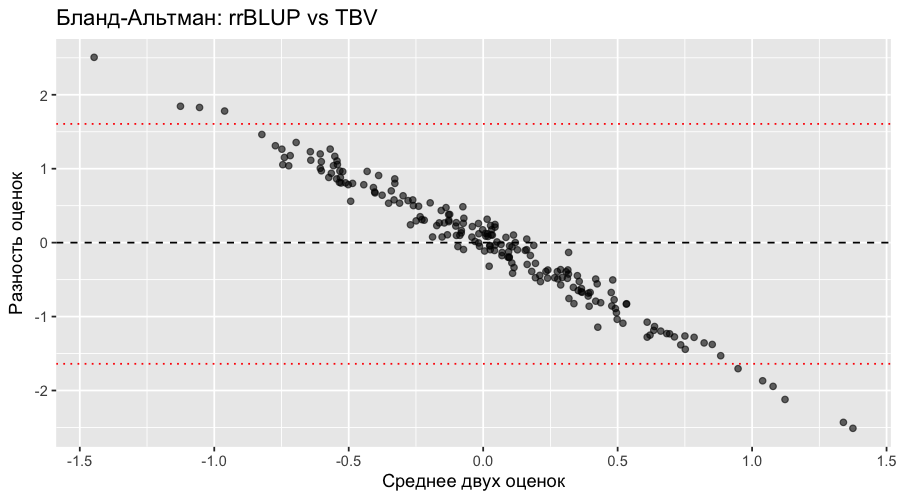

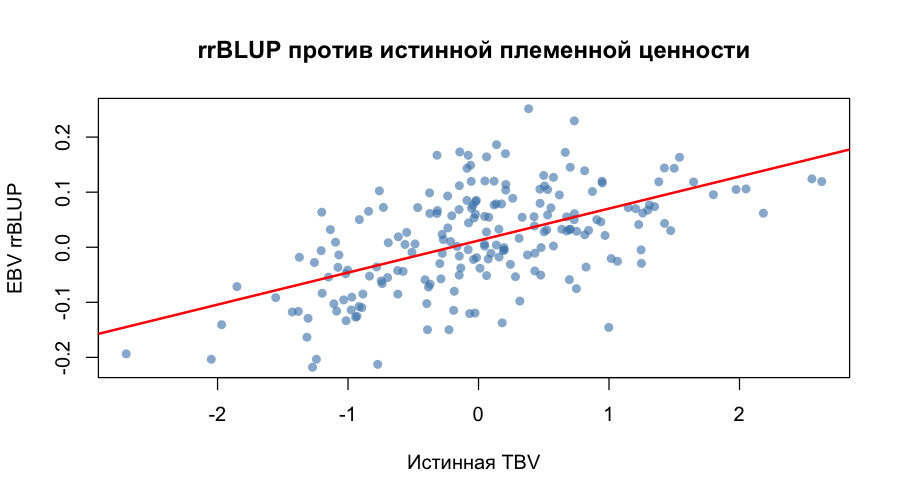

In [19]:
relevance_func(compare_rrblup_true, 'ebv_rrblup', 'ebv_true')
correlation_func(compare_rrblup_true, 'ebv_rrblup', 'ebv_true')
linear_regression_func(compare_rrblup_true, 'ebv_rrblup', 'ebv_true')
bland_altman_plot_func(compare_rrblup_true, 'ebv_rrblup', 'ebv_true', 'Бланд-Альтман: rrBLUP vs TBV')
plot_func(
  compare_rrblup_true, 'ebv_rrblup', 'ebv_true',
  xlab = 'Истинная TBV', ylab = 'EBV rrBLUP',
  title = 'rrBLUP против истинной племенной ценности'
)


Корреляция Спирмена rrBLUP с истинной TBV равна **`round(spearman_rrblup_true, 4)`**. Чем ближе значение к 1, тем лучше метод ранжирует животных в том же порядке, в каком они были смоделированы.

## 5.2. somer и истинная племенная ценность


[1] "Распределение нормальное. Применён тест Стьюдента"



	Paired t-test

data:  dataset[[var_1]] and dataset[[var_2]]
t = -0.28101, df = 199, p-value = 0.779
alternative hypothesis: true mean difference is not equal to 0
95 percent confidence interval:
 -0.13183360  0.09894627
sample estimates:
mean difference 
    -0.01644367 



[1] 0.5373404



Call:
lm(formula = dataset[[var_1]] ~ dataset[[var_2]])

Residuals:
     Min       1Q   Median       3Q      Max 
-0.21703 -0.04771 -0.01215  0.05229  0.21818 

Coefficients:
                 Estimate Std. Error t value Pr(>|t|)    
(Intercept)      0.012239   0.005375   2.277   0.0239 *  
dataset[[var_2]] 0.058486   0.006153   9.505   <2e-16 ***
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

Residual standard error: 0.07597 on 198 degrees of freedom
Multiple R-squared:  0.3133,	Adjusted R-squared:  0.3099 
F-statistic: 90.35 on 1 and 198 DF,  p-value: < 2.2e-16



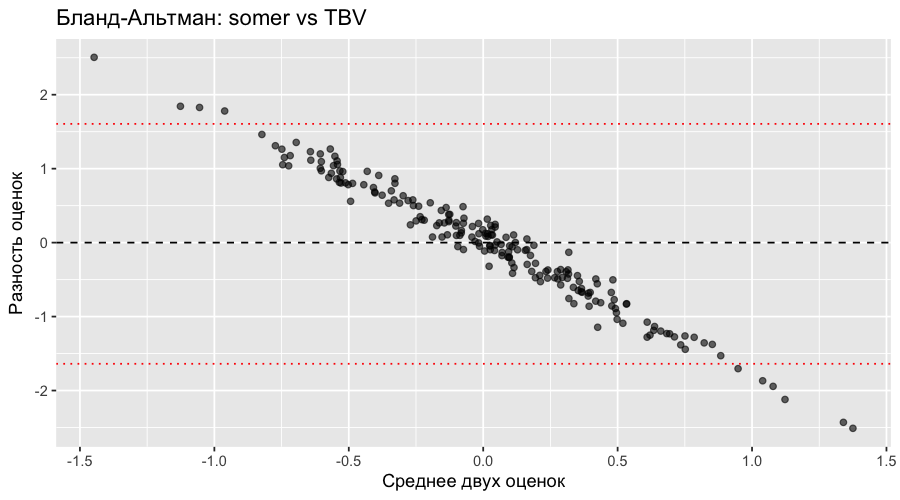

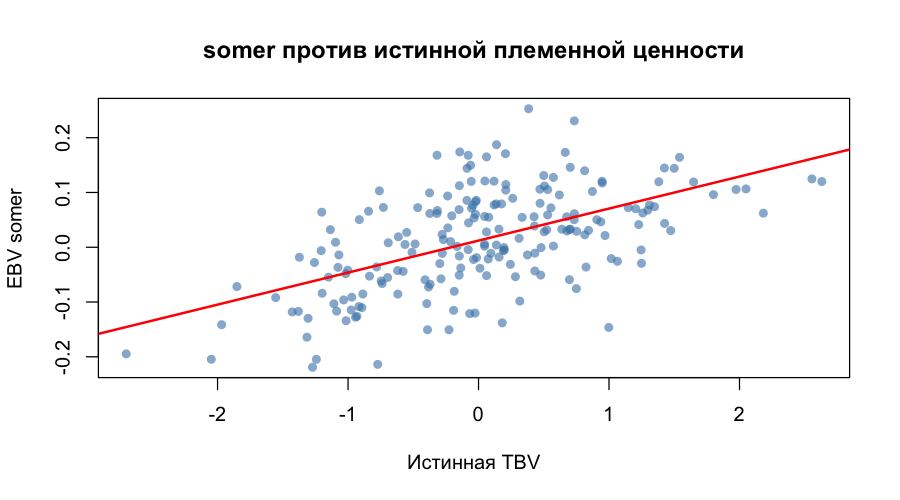

In [20]:
relevance_func(compare_somer_true, 'ebv_somer', 'ebv_true')
correlation_func(compare_somer_true, 'ebv_somer', 'ebv_true')
linear_regression_func(compare_somer_true, 'ebv_somer', 'ebv_true')
bland_altman_plot_func(compare_somer_true, 'ebv_somer', 'ebv_true', 'Бланд-Альтман: somer vs TBV')
plot_func(
  compare_somer_true, 'ebv_somer', 'ebv_true',
  xlab = 'Истинная TBV', ylab = 'EBV somer',
  title = 'somer против истинной племенной ценности'
)


Корреляция Спирмена somer с истинной TBV равна **`round(spearman_somer_true, 4)`**.

## 5.3. rrBLUP и somer

Это сравнение отвечает на вопрос, дают ли две R-библиотеки согласованный ранжир на одних и тех же данных.


[1] "Распределение нормальное. Применён тест Стьюдента"



	Paired t-test

data:  dataset[[var_1]] and dataset[[var_2]]
t = -2.1803, df = 199, p-value = 0.03041
alternative hypothesis: true mean difference is not equal to 0
95 percent confidence interval:
 -1.439409e-04 -7.223793e-06
sample estimates:
mean difference 
  -7.558232e-05 



[1] 0.9999985



Call:
lm(formula = dataset[[var_1]] ~ dataset[[var_2]])

Residuals:
       Min         1Q     Median         3Q        Max 
-4.926e-05 -1.219e-05 -1.137e-06  1.372e-05  5.555e-05 

Coefficients:
                   Estimate Std. Error   t value Pr(>|t|)    
(Intercept)      -4.819e-07  1.440e-06    -0.335    0.738    
dataset[[var_2]]  9.946e-01  1.560e-05 63758.786   <2e-16 ***
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

Residual standard error: 2.012e-05 on 198 degrees of freedom
Multiple R-squared:      1,	Adjusted R-squared:      1 
F-statistic: 4.065e+09 on 1 and 198 DF,  p-value: < 2.2e-16



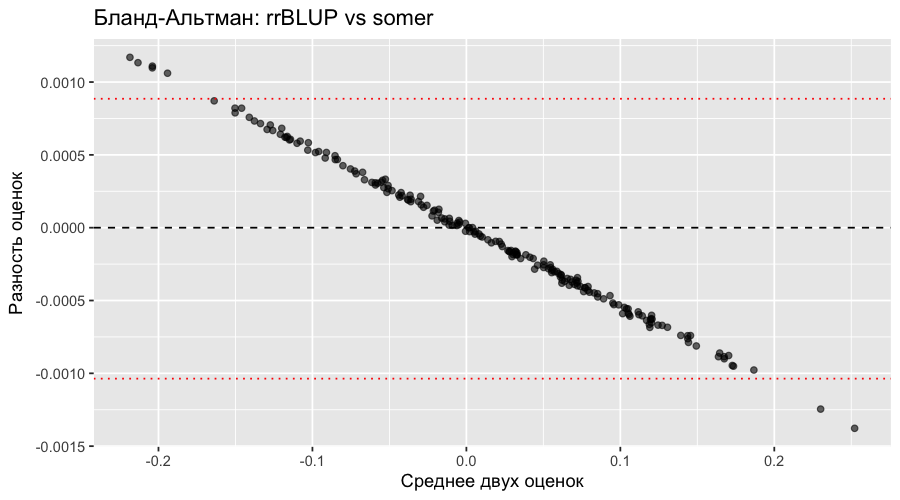

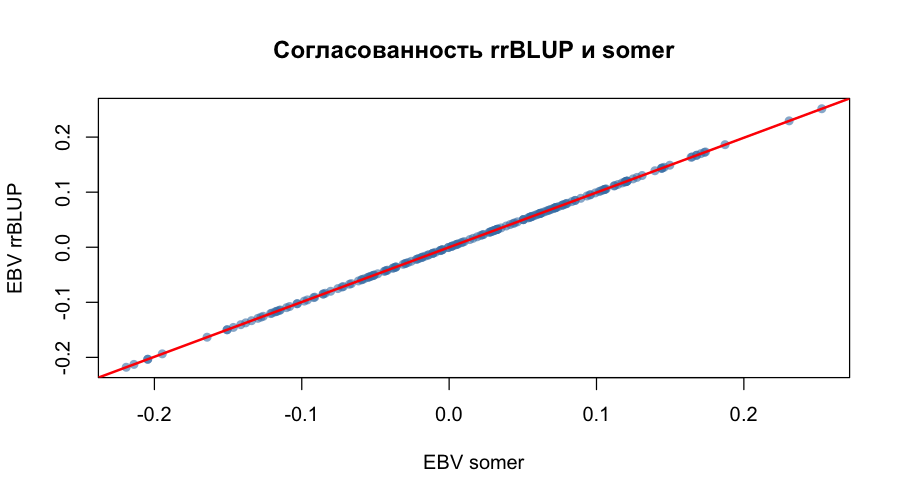

In [21]:
relevance_func(compare_rrblup_somer, 'ebv_rrblup', 'ebv_somer')
correlation_func(compare_rrblup_somer, 'ebv_rrblup', 'ebv_somer')
linear_regression_func(compare_rrblup_somer, 'ebv_rrblup', 'ebv_somer')
bland_altman_plot_func(compare_rrblup_somer, 'ebv_rrblup', 'ebv_somer', 'Бланд-Альтман: rrBLUP vs somer')
plot_func(
  compare_rrblup_somer, 'ebv_rrblup', 'ebv_somer',
  xlab = 'EBV somer', ylab = 'EBV rrBLUP',
  title = 'Согласованность rrBLUP и somer'
)


Корреляция Спирмена между rrBLUP и somer равна **`round(spearman_rrblup_somer, 4)`**. Высокое значение означает, что для селекционного отбора две реализации BLUP в R ведут себя почти одинаково; расхождения тогда скорее в масштабе шкалы, чем в порядке животных.

# 6. Краткий вывод

1. **Производительность.** На больших N BLUPF90 остаётся быстрее rrBLUP и somer. R-пакеты удобнее для разбора модели, но хуже масштабируются.

2. **Валидация.** На сгенерированных `n_animals` животных обе R-библиотеки считаются по одной смешанной модели с матрицей родства A. Эталон — известная TBV, а не внешний файл решений.

3. **Согласованность.** rrBLUP и somer сравниваются и с истиной, и друг с другом: по ранжированию (Спирмен), по шкале (регрессия) и по попарным расхождениям (Бланд–Альтман).
